# Diabetic Retinopathy using ResNet50

## 1. Import Library

In [18]:
import tensorflow as tf 
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import pickle
import numpy as np
import matplotlib.pyplot as plt

## 2. Load Data 

In [19]:
with open("../../../data/processed/aptos/sample_200/sample_dataset.pkl", "rb") as f: #[cite: 1]
    data = pickle.load(f)

In [20]:
with open("../../../data/processed/aptos/test_images/sample_dataset.pkl", "rb") as f:
    data_test = pickle.load(f)

## 3. Data Preprocessing

In [21]:
x_train = data['data']
y_train = data['labels']
class_names = data['class_names']
NUM_CLASSES = len(class_names)
IMG_SIZE = x_train.shape[1]
print(f'Số mẫu: {len(y_train)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 954 | Số lớp: 5 | Kích thước ảnh: 300x300


In [22]:
x_train

array([[[[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],

        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],

        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],

        ...,

        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],

        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],

        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]]],


       [[[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],

        [[0, 0, 0],
         [0,

In [23]:
x_test = data_test['data']
y_test = data_test['labels']
print(f'Số mẫu: {len(y_test)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 366 | Số lớp: 5 | Kích thước ảnh: 300x300


In [24]:
x_train = preprocess_input(x_train.astype('float32'))
x_test  = preprocess_input(x_test.astype('float32'))
y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test  = tf.keras.utils.to_categorical(y_test,  NUM_CLASSES)

In [25]:
x_train[3]

array([[[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ]],

       [[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ]],

       [[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ]],

       ...,

       [[-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        ...,
        [-103.939, -116.779, -123.68 ],
        [-103.939, -116.779, -123.68 ],
        [

In [26]:
y_train.shape

(954, 5)

In [27]:
y_test.shape

(366, 5)

### Ảnh tệp train 

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..133.22101].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..131.32].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..138.22101].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..131.32].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..131.32].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..128.32].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-119.68..151.061].
Clipping input data 

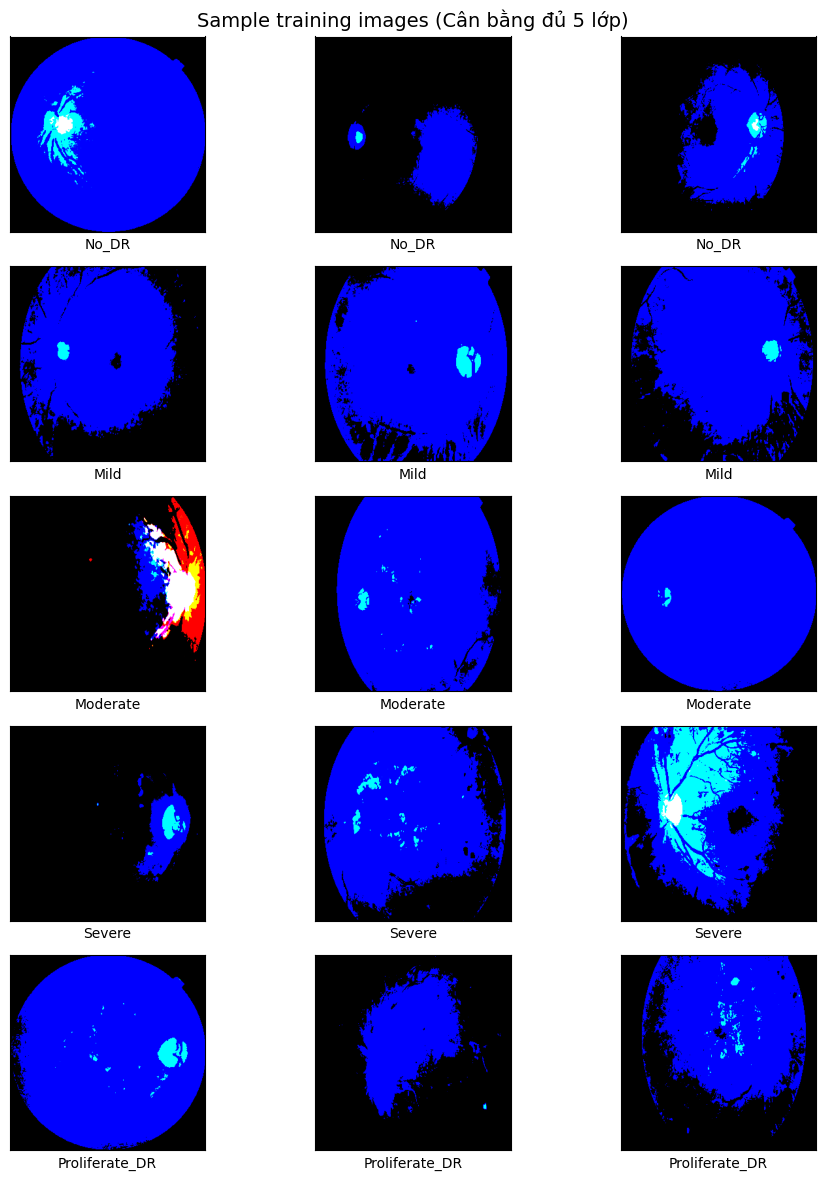

In [28]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_train, axis=1) if len(y_train.shape) > 1 else y_train

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_train[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample training images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

### Ảnh tệp test

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..131.32].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..139.061].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..131.32].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..131.32].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..131.32].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-117.68..131.32].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-123.68..131.32].
Clipping input data to the

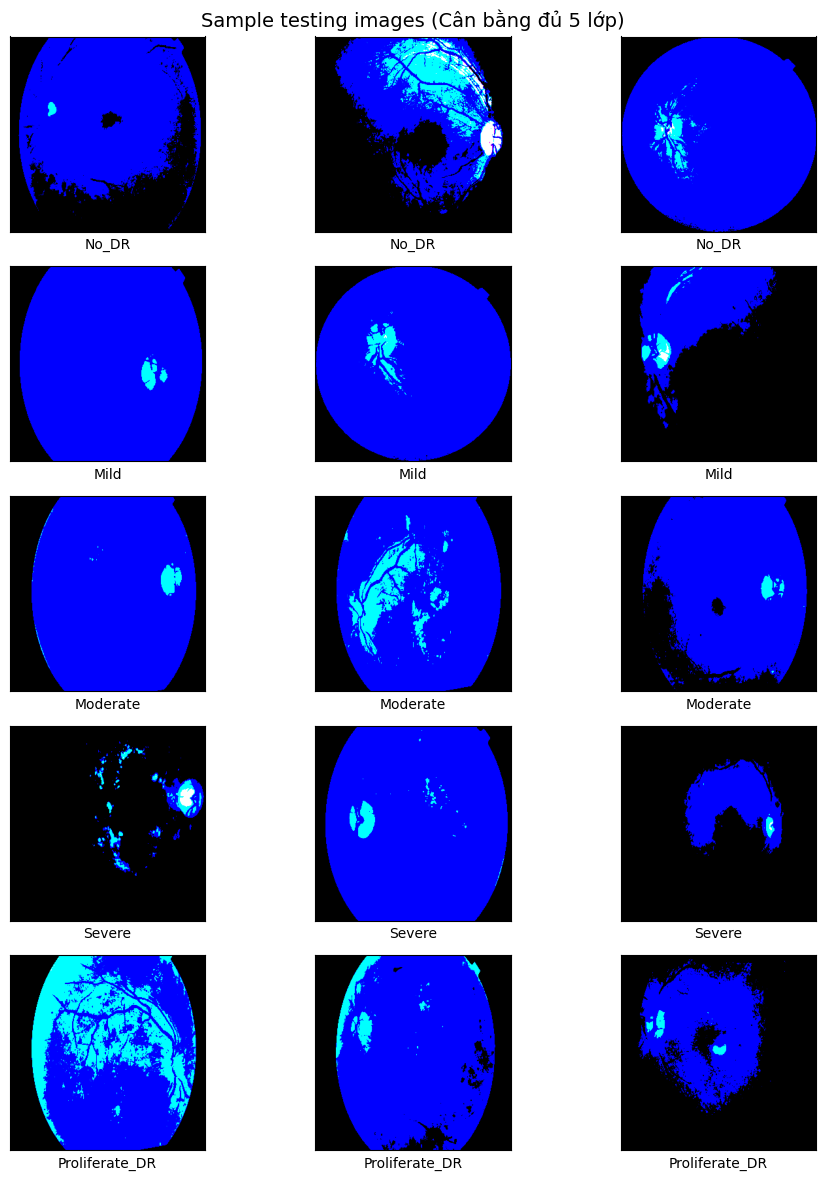

In [29]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_test[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample testing images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Xây dựng ResNet50

In [30]:
def build_reset50_baseline(input_shape, num_classes):
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    base_model.trainable = False
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.5)(x) 
    x = BatchNormalization()(x)
    
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    # Lớp đầu ra 5 classes tương ứng với 5 độ bệnh
    predictions = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=predictions)
    
    # Sử dụng Adam với learning rate nhỏ để fine-tune mượt mà hơn
    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [31]:
model = build_reset50_baseline((IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 306, 306,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 150, 150,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 150, 150,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 150, 150,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 152, 152,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 75, 75,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 75, 75,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 75, 75,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 75, 75,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 75, 75,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 75, 75,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 75, 75,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 75, 75,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 75, 75,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 75, 75,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 75, 75,    │      1,024 │ conv2_block1_3_c

 Total params: 24,779,653 (94.53 MB)

 Trainable params: 1,186,821 (4.53 MB)

 Non-trainable params: 23,592,832 (90.00 MB)

## 5. Compile & Train 

In [32]:
model.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/resnet50_aptos_200_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=5, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=15, 
        restore_best_weights=True, verbose=1
    )
]
history = model.fit(
    x_train,
    y_train, 
    epochs=100, 
    batch_size=4,
    validation_split=0.2,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1784797168.297851    3071 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_39278__.198
I0000 00:00:1784797181.555242    3071 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_39278__.198



Epoch 1: val_accuracy improved from None to 0.00000, saving model to ../../../data/models/resnet50_aptos_200_best.keras

Epoch 1: finished saving model to ../../../data/models/resnet50_aptos_200_best.keras
191/191 - 36s - 190ms/step - accuracy: 0.4351 - loss: 1.5231 - val_accuracy: 0.0000e+00 - val_loss: 4.5426 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy did not improve from 0.00000
191/191 - 9s - 46ms/step - accuracy: 0.5347 - loss: 1.2999 - val_accuracy: 0.0000e+00 - val_loss: 5.3953 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy did not improve from 0.00000
191/191 - 9s - 46ms/step - accuracy: 0.5269 - loss: 1.2338 - val_accuracy: 0.0000e+00 - val_loss: 5.9069 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: val_accuracy did not improve from 0.00000
191/191 - 9s - 45ms/step - accuracy: 0.5623 - loss: 1.1504 - val_accuracy: 0.0000e+00 - val_loss: 7.5720 - learning_rate: 0.0010
Epoch 5/100

Epoch 5: val_accuracy did not improve from 0.00000
191/191 - 9s - 45ms

## 6. Visualize Training

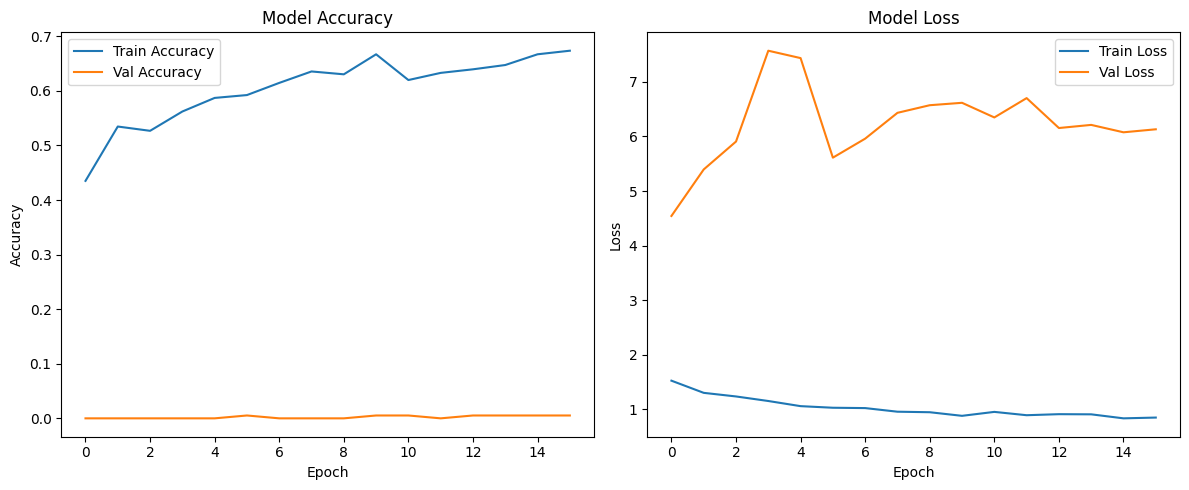

In [33]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

## 7. Evaluate on Test Set

In [34]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_acc:.4f}') 

Test Loss: 1.1578
Test Accuracy: 0.6257
